<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/3_2_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
!apt-get update
!apt-get install -y libopencv-dev

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 37 not upgraded.


In [11]:
%%writefile gorev2.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <cmath> // round() fonksiyonu için

using namespace cv;
using namespace std;

int main() {
    // 1. Görüntüyü tek kanallı oku
    Mat image = imread("resim.jpg", IMREAD_GRAYSCALE);

    if (image.empty()) {
        cout << "Görüntü okunamadı! Lütfen dosya yolunu kontrol edin." << endl;
        return -1;
    }

    // 2. 256 Değerli Histogramı Çıkarma
    int histogram[256] = {0}; // Tüm değerleri 0 ile başlatıyoruz

    for (int r = 0; r < image.rows; r++) {
        for (int c = 0; c < image.cols; c++) {
            int pixel_value = image.at<uchar>(r, c);
            histogram[pixel_value]++; // O pikselin değerine ait sayacı 1 artır
        }
    }

    // 3. Kümülatif Dağılım Değerlerini (CDF) Hesaplama
    int cdf[256] = {0};
    cdf[0] = histogram[0]; // İlk değer histogramın ilk değerine eşittir

    for (int i = 1; i < 256; i++) {
        cdf[i] = cdf[i - 1] + histogram[i]; // Bir önceki cdf ile güncel histogramı topla
    }

    // CDF_min (Sıfırdan farklı en küçük CDF değeri) bulma
    int cdf_min = 0;
    for (int i = 0; i < 256; i++) {
        if (cdf[i] > 0) {
            cdf_min = cdf[i];
            break; // İlk 0 olmayan değeri bulduk, döngüden çık
        }
    }

    int total_pixels = image.rows * image.cols; // MxN (Toplam piksel sayısı)

    // 4. Eşitleme (Mapping) için Dönüşüm Tablosu Oluşturma
    int transform_map[256] = {0};
    for (int i = 0; i < 256; i++) {
        // Yeni piksel değerini CDF formülü ile hesapla
        double mapped_value = round((double)(cdf[i] - cdf_min) / (total_pixels - cdf_min) * 255.0);

        // Değerin 0-255 aralığında kalmasını garanti altına al (taşmaları önle)
        if (mapped_value < 0) mapped_value = 0;
        if (mapped_value > 255) mapped_value = 255;

        transform_map[i] = (int)mapped_value;
    }

    // 5. Yeni (Eşitlenmiş) Görüntüyü Oluşturma
    Mat equalized_image = Mat::zeros(image.size(), image.type());

    for (int r = 0; r < image.rows; r++) {
        for (int c = 0; c < image.cols; c++) {
            int original_pixel = image.at<uchar>(r, c);
            // Dönüşüm tablosundaki yeni karşılığını atıyoruz
            equalized_image.at<uchar>(r, c) = transform_map[original_pixel];
        }
    }

    // 6. Çıktı Resmi Kaydetme
    imwrite("sonuc_esitlenmis.jpg", equalized_image);
    cout << "Histogram esitleme basariyla tamamlandi! Sonuclar 'sonuc_esitlenmis.jpg' olarak kaydedildi." << endl;

    return 0;
}

Overwriting gorev2.cpp


In [12]:
!g++ gorev2.cpp -o gorev2 `pkg-config --cflags --libs opencv4`
!./gorev2

Histogram esitleme basariyla tamamlandi! Sonuclar 'sonuc_esitlenmis.jpg' olarak kaydedildi.


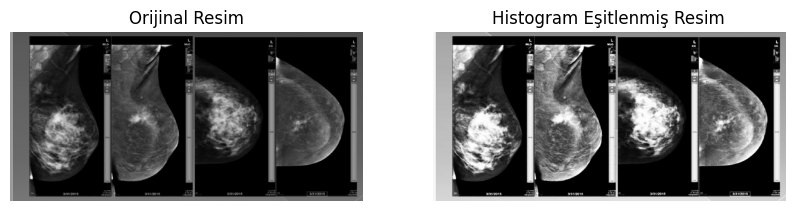

In [13]:
import cv2
import matplotlib.pyplot as plt

orijinal = cv2.imread('resim.jpg', cv2.IMREAD_GRAYSCALE)
esitlenmis = cv2.imread('sonuc_esitlenmis.jpg', cv2.IMREAD_GRAYSCALE)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(orijinal, cmap='gray', vmin=0, vmax=255)
ax1.set_title('Orijinal Resim')
ax1.axis('off')

ax2.imshow(esitlenmis, cmap='gray', vmin=0, vmax=255)
ax2.set_title('Histogram Eşitlenmiş Resim')
ax2.axis('off')

plt.show()